# NMR echo-train phase rotation and T2 inversion

This tutorial starts with eight source T2-bin porosities, synthesizes a dual-channel echo train, adds independent Gaussian noise to the X and Y channels, estimates and corrects the phase, stacks neighboring depth samples, and inverts the corrected in-phase echoes into a T2 distribution and an NMR log.

The notebook deliberately separates three processing parameters that are easy to mix together:

1. **Phase angle** rotates a complex signal between X and Y.
2. **Noise standard deviation** controls the Gaussian noise in each channel.
3. **Regularization alpha** stabilizes the least-squares inversion.

The acquisition is intentionally idealized: the phase is constant, X and Y
have equal gain and independent equal-variance noise. The inversion can use
either the legacy eight-bin basis or a finer logarithmic T2 grid.


## Processing sequence

For bin amplitudes $(p_j)$ and relaxation times $(T_{2,j})$, the noiseless
echo at time $(t_i)$ is

$$
s(t_i)=\sum_j p_j\exp(-t_i/T_{2,j}).
$$

A phase angle $\theta\$ produces the complex signal

$$
z=s\exp(i\theta)=X+iY.
$$

After independent noise is added to X and Y, phase correction multiplies the
complex channel by $\exp(-i\hat\theta)$. Correct phase alignment moves the
expected signal into the real, or in-phase, channel. It does **not** remove
noise from that channel; stacking is the operation used here to reduce noise.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPythonImage, display
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.optimize import curve_fit, least_squares, lsq_linear, minimize

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110})


## Configuration

Change settings only in this cell. Later cells consume these names without
redefining them. The recommended default is regularized nonnegative linear
least squares (`lsq_linear`).

`INVERSION_GRID_MODE = "legacy_8_bin"` reproduces the historical workflow in
which the inversion solves directly for porosity in the eight reporting bins.
`"fine_log"` instead solves on a configurable logarithmic T2 grid; the default
is 64 components from 1 to 3000 ms. The source grid and inversion grid remain
separate, so the fine-grid example is not given the exact basis that generated
the synthetic echo. `REGULARIZATION_ALPHA = None` selects a documented
demonstration value for the chosen grid; replace it with a number when testing
an alpha selected for your acquisition and noise level.


In [2]:
DATA_FILE = Path("nmr.csv")

# Acquisition and synthetic-channel settings
SOURCE_T2_BIN_MS = np.array([4, 8, 16, 32, 64, 128, 256, 512], dtype=float)
NUM_ECHOES = 300
ECHO_SPACING_MS = 1.2
PHASE_ANGLE_DEG = 30.0
PHASE_CORRECTION_MODE = "estimate"  # "estimate" or "known"
PHASE_ESTIMATION_ECHOES = 64         # use early, higher-SNR echoes
NOISE_STD = 1.0                      # 1-sigma noise per X/Y channel, porosity units
RANDOM_SEED = 42

# Depth stacking: adjacent log samples are averaged, trading vertical resolution for SNR
STACK_LEVELS = 3

# Inversion grid: retain the historical eight-bin workflow or use a modern fine grid
INVERSION_GRID_MODE = "fine_log"      # "legacy_8_bin" or "fine_log"
FINE_T2_MIN_MS = 1.0
FINE_T2_MAX_MS = 3000.0
FINE_T2_BIN_COUNT = 64

# Inversion settings
INVERSION_METHOD = "lsq_linear"       # preferred; alternatives below
REGULARIZATION_ALPHA = None           # None selects the demonstration default below; or set a float
LEGACY_ALPHA_DEFAULT = 0.15
FINE_GRID_ALPHA_DEFAULT = 2.0
REGULARIZATION_MODE = "auto"          # "auto", "hybrid", 0 (amplitude), 1, or 2
CURVATURE_WEIGHT = 1.0                 # relative D2 weight when hybrid is selected
OPTIMIZE_LAMBDA = 0.12                # used only by optimize
MAX_BIN_POROSITY = 50.0

# Log partition and plotting settings
T2_CUTOFF_MS = 33.0
CUTOFF_PARTITION_MODE = "fractional_log_bin"  # see partition section for alternatives
SHADE_OPACITY = 0.20

# Level-by-level teaching animation
CREATE_LEVEL_ANIMATION = True
ANIMATION_FRAME_MS = 300
ANIMATION_DPI = 100

assert PHASE_CORRECTION_MODE in {"estimate", "known"}
assert INVERSION_GRID_MODE in {"legacy_8_bin", "fine_log"}
assert INVERSION_METHOD in {"lsq_linear", "least_squares", "optimize", "curve_fit"}
assert REGULARIZATION_MODE in {"auto", "hybrid", 0, 1, 2}
assert CUTOFF_PARTITION_MODE in {
    "fractional_log_bin",
    "whole_bin_center",
    "legacy_between_centers",
}
assert T2_CUTOFF_MS > 0
assert 1 <= STACK_LEVELS
assert 1 <= PHASE_ESTIMATION_ECHOES <= NUM_ECHOES

if INVERSION_GRID_MODE == "legacy_8_bin":
    INVERSION_T2_MS = SOURCE_T2_BIN_MS.copy()
else:
    INVERSION_T2_MS = np.geomspace(
        FINE_T2_MIN_MS, FINE_T2_MAX_MS, FINE_T2_BIN_COUNT
    )

regularization_mode_used = (
    0 if INVERSION_GRID_MODE == "legacy_8_bin" else "hybrid"
) if REGULARIZATION_MODE == "auto" else REGULARIZATION_MODE
regularization_alpha_used = (
    LEGACY_ALPHA_DEFAULT
    if INVERSION_GRID_MODE == "legacy_8_bin"
    else FINE_GRID_ALPHA_DEFAULT
) if REGULARIZATION_ALPHA is None else float(REGULARIZATION_ALPHA)

settings = pd.Series({
    "inversion_method": INVERSION_METHOD,
    "inversion_grid_mode": INVERSION_GRID_MODE,
    "inversion_grid_bins": len(INVERSION_T2_MS),
    "inversion_t2_min_ms": INVERSION_T2_MS.min(),
    "inversion_t2_max_ms": INVERSION_T2_MS.max(),
    "regularization_alpha": regularization_alpha_used,
    "regularization_mode": regularization_mode_used,
    "curvature_weight": CURVATURE_WEIGHT,
    "phase_angle_deg": PHASE_ANGLE_DEG,
    "phase_correction_mode": PHASE_CORRECTION_MODE,
    "noise_std_per_channel": NOISE_STD,
    "stack_levels": STACK_LEVELS,
    "echo_spacing_ms": ECHO_SPACING_MS,
    "num_echoes": NUM_ECHOES,
    "random_seed": RANDOM_SEED,
    "create_level_animation": CREATE_LEVEL_ANIMATION,
    "animation_frame_ms": ANIMATION_FRAME_MS,
    "t2_cutoff_ms": T2_CUTOFF_MS,
    "cutoff_partition_mode": CUTOFF_PARTITION_MODE,
}, name="value")
settings.to_frame()


,value
inversion_method,lsq_linear
inversion_grid_mode,fine_log
inversion_grid_bins,64
inversion_t2_min_ms,1.0
inversion_t2_max_ms,3000.0
regularization_alpha,2.0
regularization_mode,hybrid
curvature_weight,1.0
phase_angle_deg,30.0
phase_correction_mode,estimate


## Load and validate the bin data

`MPHI`, `MBVI`, and `MFFI` from the input file are retained as reference curves.
The inversion itself uses only depth and the eight P-bin columns.


In [3]:
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_FILE.resolve()}. Place nmr.csv beside this notebook."
    )

df = pd.read_csv(DATA_FILE)
BIN_COLUMNS = [f"P{i}" for i in range(1, 9)]
REQUIRED_COLUMNS = ["Depth", *BIN_COLUMNS]
missing = sorted(set(REQUIRED_COLUMNS) - set(df.columns))
if missing:
    raise ValueError(f"Missing required columns: {missing}")
if df[REQUIRED_COLUMNS].isna().any().any():
    raise ValueError("Depth and T2-bin columns must not contain missing values.")
if (df[BIN_COLUMNS] < 0).any().any():
    raise ValueError("T2-bin porosities must be nonnegative.")

depth = df["Depth"].to_numpy(dtype=float)
input_bins = df[BIN_COLUMNS].to_numpy(dtype=float)
input_mphi_from_bins = input_bins.sum(axis=1)

print(f"Loaded {len(df)} depth samples from {depth.min():.1f} to {depth.max():.1f}.")
print(
    "Maximum |MPHI - sum(P1..P8)|:",
    f"{np.max(np.abs(df['MPHI'].to_numpy() - input_mphi_from_bins)):.4f} pu"
    if "MPHI" in df else "MPHI not supplied",
)
df.head()


Loaded 51 depth samples from 7177.0 to 7202.0.
Maximum |MPHI - sum(P1..P8)|: 0.0020 pu


,Depth,MPHI,P1,P2,P3,P4,P5,P6,P7,P8,MFFI,MBVI
0,7177.0,3.294,0.7960,0.6230,0.1180,0.0130,0.0160,0.172,0.5560,0.9980,1.756,1.5370
1,7177.5,3.002,0.3010,0.3500,0.2220,0.1540,0.2040,0.392,0.6140,0.7650,2.129,0.8730
2,7178.0,3.289,0.0620,0.2170,0.3430,0.3800,0.4260,0.528,0.6300,0.7020,2.668,0.6220
3,7178.5,4.568,0.0480,0.3030,0.6280,0.7910,0.7770,0.715,0.6670,0.6390,3.590,0.9790
4,7179.0,5.397,0.1835,0.3435,0.6465,0.9735,1.0485,0.902,0.7175,0.5825,4.224,1.1735


## 1. Create noiseless echo trains from the bin data

A physical echo train begins at one echo spacing, not at zero time. Therefore
the first modeled echo is at 1.2 ms when `ECHO_SPACING_MS = 1.2`.


In [4]:
time_ms = (np.arange(NUM_ECHOES) + 1) * ECHO_SPACING_MS
source_kernel = np.exp(-time_ms[:, None] / SOURCE_T2_BIN_MS[None, :])
inversion_kernel = np.exp(-time_ms[:, None] / INVERSION_T2_MS[None, :])
noiseless_echoes = input_bins @ source_kernel.T

assert noiseless_echoes.shape == (len(df), NUM_ECHOES)
print(f"Echo times: {time_ms[0]:.1f} to {time_ms[-1]:.1f} ms")
print("Source-kernel condition number:", f"{np.linalg.cond(source_kernel):.1f}")
print("Inversion-kernel condition number:", f"{np.linalg.cond(inversion_kernel):.2e}")


Echo times: 1.2 to 360.0 ms
Source-kernel condition number: 1794.6
Inversion-kernel condition number: 5.72e+17


## 2. Create noisy X and Y channels

A single seeded random-number generator makes the tutorial reproducible.
`NOISE_STD` is the standard deviation of the noise in **each** quadrature
channel. Creating two arrays explicitly makes their purpose clearer than
creating one array twice as long and slicing it; both approaches are
statistically equivalent for independent draws.


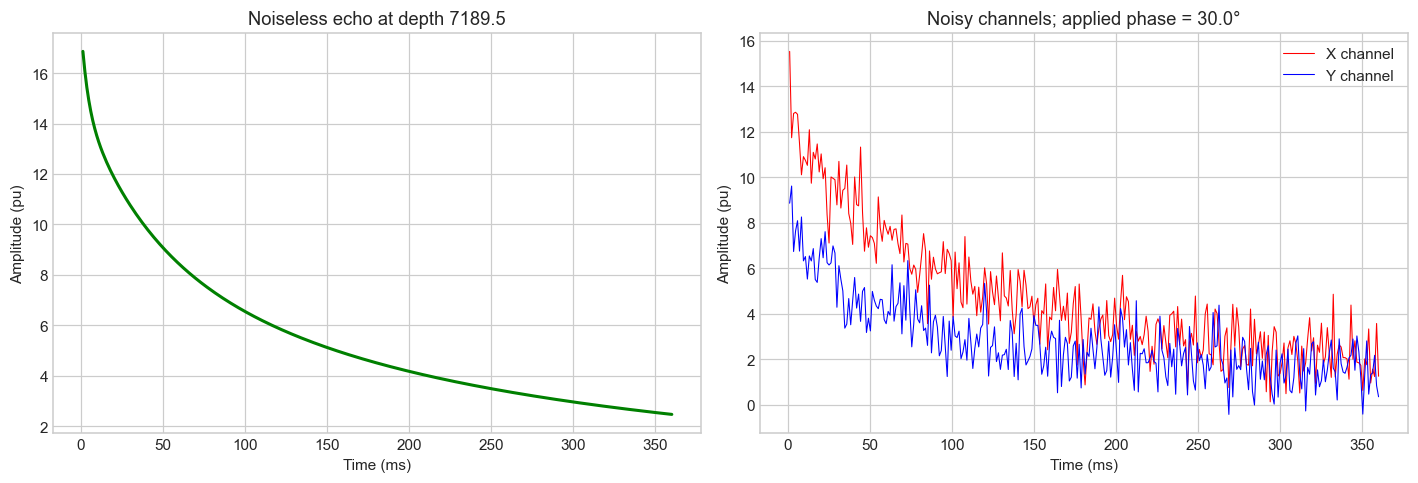

In [5]:
rng = np.random.default_rng(RANDOM_SEED)
phase_angle_rad = np.deg2rad(PHASE_ANGLE_DEG)

noise_x = rng.normal(0.0, NOISE_STD, size=noiseless_echoes.shape)
noise_y = rng.normal(0.0, NOISE_STD, size=noiseless_echoes.shape)

x_channel = noiseless_echoes * np.cos(phase_angle_rad) + noise_x
y_channel = noiseless_echoes * np.sin(phase_angle_rad) + noise_y
complex_channel = x_channel + 1j * y_channel

example_row = len(df) // 2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(time_ms, noiseless_echoes[example_row], color="green", lw=2)
axes[0].set(title=f"Noiseless echo at depth {depth[example_row]:.1f}",
            xlabel="Time (ms)", ylabel="Amplitude (pu)")
axes[1].plot(time_ms, x_channel[example_row], color="red", lw=0.7, label="X channel")
axes[1].plot(time_ms, y_channel[example_row], color="blue", lw=0.7, label="Y channel")
axes[1].set(title=f"Noisy channels; applied phase = {PHASE_ANGLE_DEG:.1f}°",
            xlabel="Time (ms)", ylabel="Amplitude (pu)")
axes[1].legend()
plt.tight_layout()
plt.show()


## 3. Estimate and correct the phase

Because the synthetic decay is positive and the phase is constant, the phase
can be estimated from the argument of the summed early-echo complex signal.
Combining all depths improves the estimate. A field workflow may instead need
local depth windows, offset removal, gain correction, or a more robust phase
estimator.

Selecting `PHASE_CORRECTION_MODE = "known"` uses the applied synthetic angle
directly. Selecting `"estimate"` demonstrates recovery from X and Y.


Applied phase:     30.000°
Estimated phase:   30.294°
Estimation error:   0.294°
Correction used:   30.294° (estimate)


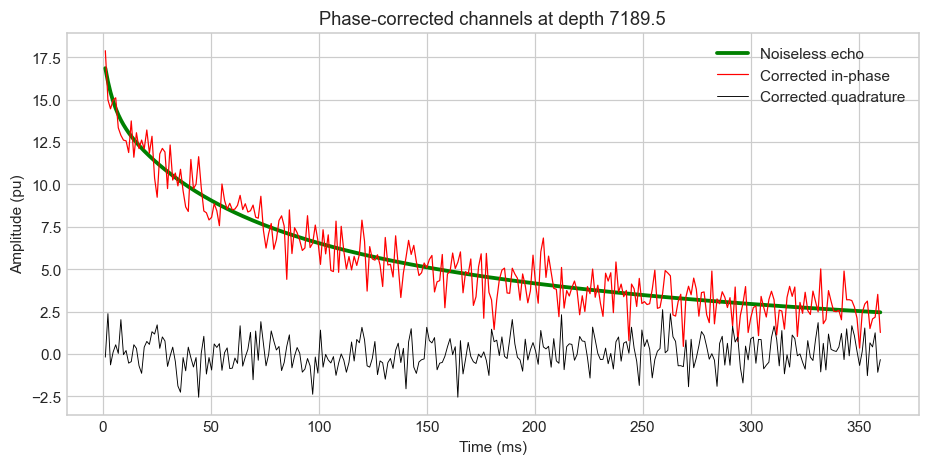

In [6]:
def estimate_constant_phase(x, y, number_of_early_echoes):
    z_early = x[:, :number_of_early_echoes] + 1j * y[:, :number_of_early_echoes]
    return float(np.angle(z_early.sum()))


estimated_phase_rad = estimate_constant_phase(
    x_channel, y_channel, PHASE_ESTIMATION_ECHOES
)
correction_phase_rad = (
    phase_angle_rad
    if PHASE_CORRECTION_MODE == "known"
    else estimated_phase_rad
)

corrected_complex = complex_channel * np.exp(-1j * correction_phase_rad)
in_phase_echoes = corrected_complex.real
quadrature_echoes = corrected_complex.imag

estimated_phase_deg = np.rad2deg(estimated_phase_rad)
correction_phase_deg = np.rad2deg(correction_phase_rad)
phase_error_deg = estimated_phase_deg - PHASE_ANGLE_DEG

print(f"Applied phase:   {PHASE_ANGLE_DEG:8.3f}°")
print(f"Estimated phase: {estimated_phase_deg:8.3f}°")
print(f"Estimation error:{phase_error_deg:8.3f}°")
print(f"Correction used: {correction_phase_deg:8.3f}° ({PHASE_CORRECTION_MODE})")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(time_ms, noiseless_echoes[example_row], color="green", lw=2.5,
        label="Noiseless echo")
ax.plot(time_ms, in_phase_echoes[example_row], color="red", lw=0.8,
        label="Corrected in-phase")
ax.plot(time_ms, quadrature_echoes[example_row], color="black", lw=0.6,
        label="Corrected quadrature")
ax.set(title=f"Phase-corrected channels at depth {depth[example_row]:.1f}",
       xlabel="Time (ms)", ylabel="Amplitude (pu)")
ax.legend()
plt.show()


### What phase correction does to noise

With independent X/Y noise of equal variance, rotation preserves the noise
variance. Correct phase alignment removes the expected signal from the
quadrature channel, but the in-phase channel remains signal plus noise.


In [7]:
in_phase_noise = in_phase_echoes - noiseless_echoes
noise_check = pd.Series({
    "configured X/Y noise std": NOISE_STD,
    "measured X noise std": noise_x.std(ddof=1),
    "measured Y noise std": noise_y.std(ddof=1),
    "corrected in-phase residual std": in_phase_noise.std(ddof=1),
    "corrected quadrature std": quadrature_echoes.std(ddof=1),
}, name="standard deviation (pu)")
noise_check.to_frame()


,standard deviation (pu)
configured X/Y noise std,1.000000
measured X noise std,1.003562
measured Y noise std,1.005107
corrected in-phase residual std,1.005103
corrected quadrature std,1.003581


## 4. Stack adjacent depth samples

Every valid window is retained, so `N` input depths produce
`N - STACK_LEVELS + 1` stacked depths. The stacked depth is the mean depth of
its window. The input bin distributions and both corrected channels are
stacked identically for fair comparison.

This type of depth stacking reduces random noise but also reduces vertical
resolution and can mix different formations.


In [8]:
def stack_over_depth(values, levels):
    values = np.asarray(values)
    if levels > len(values):
        raise ValueError("STACK_LEVELS cannot exceed the number of depth samples.")
    return np.stack([
        values[start:start + levels].mean(axis=0)
        for start in range(len(values) - levels + 1)
    ])


stacked_depth = stack_over_depth(depth[:, None], STACK_LEVELS).ravel()
stacked_in_phase = stack_over_depth(in_phase_echoes, STACK_LEVELS)
stacked_quadrature = stack_over_depth(quadrature_echoes, STACK_LEVELS)
stacked_true_bins = stack_over_depth(input_bins, STACK_LEVELS)
stacked_noiseless_echoes = stacked_true_bins @ source_kernel.T

print(f"Input depths: {len(depth)}")
print(f"Stacked depths: {len(stacked_depth)}")
print(
    "Expected ideal noise std after stacking:",
    f"{NOISE_STD / np.sqrt(STACK_LEVELS):.3f} pu",
)
print(
    "Measured stacked in-phase residual std:",
    f"{(stacked_in_phase - stacked_noiseless_echoes).std(ddof=1):.3f} pu",
)


Input depths: 51
Stacked depths: 49
Expected ideal noise std after stacking: 0.577 pu
Measured stacked in-phase residual std: 0.583 pu


## 5. Invert the stacked in-phase echo trains

Four selectable methods are available:

- `lsq_linear` is the recommended method because fixed T2 values make this a
  linear inverse problem. It solves one augmented, bounded linear system.
- `least_squares` minimizes the same residual formulation through a general
  nonlinear least-squares interface.
- `optimize` uses a still more general scalar optimizer.
- `curve_fit` performs a bounded fit with no explicit Tikhonov penalty and is
  included mainly to compare with the historical implementation.

The regularized methods minimize
\(\|y-Ap\|_2^2 + \alpha\|Lp\|_2^2\) with nonnegative bounds.

More generally, this notebook uses \(\alpha\|Lp\|_2^2\). Zeroth order
(`L = I`) dampens all amplitudes toward zero. First order penalizes changes
between adjacent log-T2 components. Second order penalizes curvature and is
useful for a fine grid, but curvature alone has an unpenalized null space.
The recommended fine-grid default here is therefore a **hybrid** matrix that
combines amplitude damping and second-difference curvature. With
`REGULARIZATION_MODE = "auto"`, eight-bin recovery uses amplitude damping and
the fine grid uses the hybrid penalty.

Regularization strength depends on the grid, noise, data scaling, and chosen
operator. An alpha selected for eight bins should not automatically be reused
as a validated field-processing value for 64 bins. Setting alpha to zero still
performs the inversion, but without the explicit penalty.


In [9]:
def make_regularization_matrix(number_of_bins, mode, curvature_weight):
    identity = np.eye(number_of_bins)
    if mode == "hybrid":
        curvature = np.diff(identity, n=2, axis=0)
        return np.vstack([identity, np.sqrt(curvature_weight) * curvature])
    return identity if mode == 0 else np.diff(identity, n=mode, axis=0)


regularization_matrix = make_regularization_matrix(
    len(INVERSION_T2_MS), regularization_mode_used, CURVATURE_WEIGHT
)


def echo_model(time, *amplitudes):
    amplitudes = np.asarray(amplitudes, dtype=float)
    return np.exp(-time[:, None] / INVERSION_T2_MS[None, :]) @ amplitudes


def invert_one_echo(y):
    initial_value = max(float(y[0]), 0.1) / len(INVERSION_T2_MS)
    p0 = np.full(len(INVERSION_T2_MS), initial_value)
    lower = np.zeros(len(INVERSION_T2_MS))
    upper = np.full(len(INVERSION_T2_MS), MAX_BIN_POROSITY)

    if INVERSION_METHOD == "lsq_linear":
        augmented_kernel = np.vstack([
            inversion_kernel,
            np.sqrt(regularization_alpha_used) * regularization_matrix,
        ])
        augmented_echo = np.concatenate([
            y,
            np.zeros(regularization_matrix.shape[0]),
        ])
        result = lsq_linear(
            augmented_kernel,
            augmented_echo,
            bounds=(lower, upper),
            method="trf",
        )
        return result.x, bool(result.success), float(
            np.sum((y - inversion_kernel @ result.x) ** 2)
        )

    if INVERSION_METHOD == "least_squares":
        def residuals(p):
            data_residual = y - inversion_kernel @ p
            regularization_residual = (
                np.sqrt(regularization_alpha_used) * regularization_matrix @ p
            )
            return np.concatenate([data_residual, regularization_residual])

        result = least_squares(residuals, p0, bounds=(lower, upper))
        return result.x, bool(result.success), float(
            np.sum((y - inversion_kernel @ result.x) ** 2)
        )

    if INVERSION_METHOD == "optimize":
        def objective(p):
            data_residual = y - inversion_kernel @ p
            regularization_residual = regularization_matrix @ p
            return float(
                data_residual @ data_residual
                + OPTIMIZE_LAMBDA
                * (regularization_residual @ regularization_residual)
            )

        result = minimize(
            objective,
            p0,
            method="L-BFGS-B",
            bounds=[(0.0, MAX_BIN_POROSITY)] * len(INVERSION_T2_MS),
        )
        return result.x, bool(result.success), float(
            np.sum((y - inversion_kernel @ result.x) ** 2)
        )

    popt, _ = curve_fit(
        echo_model,
        time_ms,
        y,
        p0=p0,
        bounds=(lower, upper),
        method="trf",
        max_nfev=10_000,
    )
    return popt, True, float(np.sum((y - inversion_kernel @ popt) ** 2))


inversion_results = [invert_one_echo(y) for y in stacked_in_phase]
recovered_bins = np.vstack([item[0] for item in inversion_results])
inversion_success = np.array([item[1] for item in inversion_results])
echo_sse = np.array([item[2] for item in inversion_results])
fitted_echoes = recovered_bins @ inversion_kernel.T

print(f"Method: {INVERSION_METHOD}")
print(f"Grid: {INVERSION_GRID_MODE} ({len(INVERSION_T2_MS)} T2 components)")
print(f"Regularization mode: {regularization_mode_used}")
print(f"Successful inversions: {inversion_success.sum()} / {len(inversion_success)}")
print(f"Median echo-fit RMSE: {np.median(np.sqrt(echo_sse / NUM_ECHOES)):.4f} pu")


Method: lsq_linear
Grid: fine_log (64 T2 components)
Regularization mode: hybrid
Successful inversions: 49 / 49
Median echo-fit RMSE: 0.5808 pu


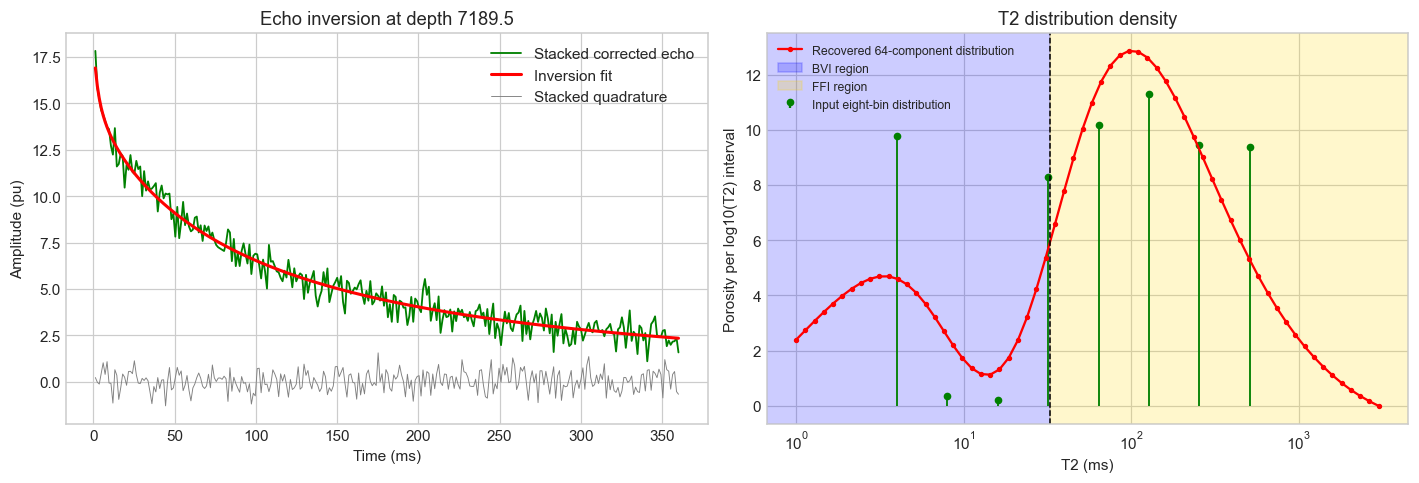

In [10]:
def logarithmic_bin_edges(t2_values):
    log_centers = np.log10(np.asarray(t2_values, dtype=float))
    log_edges = np.empty(len(log_centers) + 1)
    log_edges[1:-1] = 0.5 * (log_centers[:-1] + log_centers[1:])
    log_edges[0] = log_centers[0] - 0.5 * (log_centers[1] - log_centers[0])
    log_edges[-1] = log_centers[-1] + 0.5 * (log_centers[-1] - log_centers[-2])
    return log_edges


source_log_edges = logarithmic_bin_edges(SOURCE_T2_BIN_MS)
inversion_log_edges = logarithmic_bin_edges(INVERSION_T2_MS)
source_log_widths = np.diff(source_log_edges)
inversion_log_widths = np.diff(inversion_log_edges)
source_spectral_density = stacked_true_bins / source_log_widths[None, :]
recovered_spectral_density = recovered_bins / inversion_log_widths[None, :]

stacked_example = len(stacked_depth) // 2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(time_ms, stacked_in_phase[stacked_example], color="green", lw=1.2,
             label="Stacked corrected echo")
axes[0].plot(time_ms, fitted_echoes[stacked_example], color="red", lw=2,
             label="Inversion fit")
axes[0].plot(time_ms, stacked_quadrature[stacked_example], color="gray", lw=0.6,
             label="Stacked quadrature")
axes[0].set(title=f"Echo inversion at depth {stacked_depth[stacked_example]:.1f}",
            xlabel="Time (ms)", ylabel="Amplitude (pu)")
axes[0].legend()

markerline, stemlines, _ = axes[1].stem(
    SOURCE_T2_BIN_MS,
    source_spectral_density[stacked_example],
    linefmt="g-",
    markerfmt="go",
    basefmt=" ",
    label="Input eight-bin distribution",
)
plt.setp(stemlines, linewidth=1.2)
plt.setp(markerline, markersize=4)
axes[1].semilogx(INVERSION_T2_MS, recovered_spectral_density[stacked_example], "r-o", lw=1.5,
                 ms=2.5, label=f"Recovered {len(INVERSION_T2_MS)}-component distribution")
plot_t2_min = min(SOURCE_T2_BIN_MS.min(), INVERSION_T2_MS.min()) / 1.5
plot_t2_max = max(SOURCE_T2_BIN_MS.max(), INVERSION_T2_MS.max()) * 1.5
axes[1].axvspan(plot_t2_min, T2_CUTOFF_MS, color="blue",
               alpha=SHADE_OPACITY, label="BVI region")
axes[1].axvspan(T2_CUTOFF_MS, plot_t2_max, color="gold",
               alpha=SHADE_OPACITY, label="FFI region")
axes[1].axvline(T2_CUTOFF_MS, color="black", ls="--", lw=1)
axes[1].set_xlim(plot_t2_min, plot_t2_max)
axes[1].set(
    title="T2 distribution density",
    xlabel="T2 (ms)",
    ylabel="Porosity per log10(T2) interval",
)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


## 6. Partition the recovered distribution and construct the log

`T2_CUTOFF_MS` may be set to any positive value. The default
`fractional_log_bin` rule treats each amplitude as porosity integrated over its
logarithmic T2-bin interval. If the cutoff crosses a bin, the bin is divided in
proportion to the overlap in log-T2 space. This produces continuous BVI and FFI
values as the cutoff changes and is especially useful with the historical
eight-bin grid.

Select `whole_bin_center` when the required convention assigns an entire bin to
BVI whenever its center is at or below the cutoff. All modes conserve
`MPHI = BVI + FFI`.

Select `legacy_between_centers` to reproduce the interpolation assumption in
the original notebook: a component stated at 32 ms is treated as spanning from
32 to 64 ms, so a 33-ms cutoff assigns
`(log10(33)-log10(32))/(log10(64)-log10(32))`, about 4.44%, of that component
to BVI. This option is retained because bin-edge conventions differ among
historical data products.

The supplied file's reference `MBVI` happens to equal approximately
`P1 + P2 + P3`, which excludes its nominal 32-ms bin. That is a different bin
convention. The reference columns are preserved for comparison but are not
silently mixed with the selected partition convention used here.


In [11]:
if T2_CUTOFF_MS <= 0:
    raise ValueError("T2_CUTOFF_MS must be positive.")


def cutoff_bvi_fractions(t2_centers, log_edges, cutoff_ms, mode):
    # Return the fraction of each T2 bin assigned to BVI.
    t2_centers = np.asarray(t2_centers, dtype=float)
    if mode == "whole_bin_center":
        return (t2_centers <= cutoff_ms).astype(float)

    if mode == "legacy_between_centers":
        log_centers = np.log10(t2_centers)
        log_upper_edges = np.r_[
            log_centers[1:],
            log_centers[-1] + (log_centers[-1] - log_centers[-2]),
        ]
        return np.clip(
            (np.log10(cutoff_ms) - log_centers)
            / (log_upper_edges - log_centers),
            0.0,
            1.0,
        )

    log_cutoff = np.log10(cutoff_ms)
    log_widths = np.diff(log_edges)
    return np.clip(
        (log_cutoff - log_edges[:-1]) / log_widths,
        0.0,
        1.0,
    )


inversion_bvi_fraction = cutoff_bvi_fractions(
    INVERSION_T2_MS,
    inversion_log_edges,
    T2_CUTOFF_MS,
    CUTOFF_PARTITION_MODE,
)
source_bvi_fraction = cutoff_bvi_fractions(
    SOURCE_T2_BIN_MS,
    source_log_edges,
    T2_CUTOFF_MS,
    CUTOFF_PARTITION_MODE,
)
inversion_ffi_fraction = 1.0 - inversion_bvi_fraction
source_ffi_fraction = 1.0 - source_bvi_fraction

recovered_mphi = recovered_bins.sum(axis=1)
recovered_bvi = recovered_bins @ inversion_bvi_fraction
recovered_ffi = recovered_bins @ inversion_ffi_fraction

true_mphi = stacked_true_bins.sum(axis=1)
true_bvi = stacked_true_bins @ source_bvi_fraction
true_ffi = stacked_true_bins @ source_ffi_fraction

cutoff_label = f"{T2_CUTOFF_MS:g}ms".replace(".", "p")
input_bvi_column = f"BVI_InputBins_{cutoff_label}"
input_ffi_column = f"FFI_InputBins_{cutoff_label}"

results = pd.DataFrame({
    "Depth": stacked_depth,
    "MPHI_Inverted": recovered_mphi,
    "BVI_Inverted": recovered_bvi,
    "FFI_Inverted": recovered_ffi,
    "MPHI_InputBins": true_mphi,
    input_bvi_column: true_bvi,
    input_ffi_column: true_ffi,
    "Echo_Fit_RMSE": np.sqrt(echo_sse / NUM_ECHOES),
    "Inversion_Success": inversion_success,
})

if {"MPHI", "MBVI", "MFFI"}.issubset(df.columns):
    reference_logs = stack_over_depth(
        df[["MPHI", "MBVI", "MFFI"]].to_numpy(dtype=float),
        STACK_LEVELS,
    )
    results[["MPHI_FileReference", "MBVI_FileReference", "MFFI_FileReference"]] = reference_logs

for index, t2_value in enumerate(INVERSION_T2_MS):
    results[f"Inverted_T2_{t2_value:.5g}ms"] = recovered_bins[:, index]

for index, column in enumerate(BIN_COLUMNS):
    results[f"{column}_Input"] = stacked_true_bins[:, index]

conservation_error = np.max(
    np.abs(results["MPHI_Inverted"] - results["BVI_Inverted"] - results["FFI_Inverted"])
)
print(f"Maximum MPHI - BVI - FFI conservation error: {conservation_error:.3e} pu")
print(f"Cutoff: {T2_CUTOFF_MS:g} ms; partition mode: {CUTOFF_PARTITION_MODE}")
results.head()


Maximum MPHI - BVI - FFI conservation error: 5.329e-15 pu
Cutoff: 33 ms; partition mode: fractional_log_bin


,Depth,MPHI_Inverted,BVI_Inverted,FFI_Inverted,MPHI_InputBins,BVI_InputBins_33ms,FFI_InputBins_33ms,Echo_Fit_RMSE,Inversion_Success,MPHI_FileReference,...,Inverted_T2_2642ms,Inverted_T2_3000ms,P1_Input,P2_Input,P3_Input,P4_Input,P5_Input,P6_Input,P7_Input,P8_Input
0,7177.5,3.718169,1.569935,2.148234,3.194000,1.109928,2.084072,0.555386,True,3.195000,...,3.362751e-16,2.569810e-16,0.386333,0.396667,0.227667,0.182333,0.215333,0.364000,0.6000,0.821667
1,7178.0,4.382358,1.750394,2.631964,3.619333,1.065107,2.554226,0.549470,True,3.619667,...,6.463771e-17,4.861573e-17,0.137000,0.290000,0.397667,0.441667,0.469000,0.545000,0.6370,0.702000
2,7178.5,4.680457,1.556461,3.123995,4.417833,1.313984,3.103849,0.570648,True,4.418000,...,1.713714e-26,9.776164e-27,0.097833,0.287833,0.539167,0.714833,0.750500,0.715000,0.6715,0.641167
3,7179.0,5.566749,1.881103,3.685646,5.397500,1.703468,3.694032,0.582905,True,5.397000,...,1.537662e-18,8.790522e-19,0.183500,0.343500,0.646500,0.973500,1.048500,0.902000,0.7175,0.582500
4,7179.5,6.465410,2.009217,4.456194,6.689167,2.232550,4.456616,0.574221,True,6.688333,...,9.442712e-17,4.602698e-17,0.726167,0.352167,0.557833,1.095500,1.531500,1.243333,0.7285,0.454167


In [12]:
validation = pd.DataFrame({
    "curve": [
        "MPHI",
        f"BVI ({T2_CUTOFF_MS:g}-ms {CUTOFF_PARTITION_MODE})",
        f"FFI ({T2_CUTOFF_MS:g}-ms {CUTOFF_PARTITION_MODE})",
    ],
    "mean_absolute_error_pu": [
        np.mean(np.abs(recovered_mphi - true_mphi)),
        np.mean(np.abs(recovered_bvi - true_bvi)),
        np.mean(np.abs(recovered_ffi - true_ffi)),
    ],
    "bias_pu": [
        np.mean(recovered_mphi - true_mphi),
        np.mean(recovered_bvi - true_bvi),
        np.mean(recovered_ffi - true_ffi),
    ],
})
validation


,curve,mean_absolute_error_pu,bias_pu
0,MPHI,0.428371,0.112779
1,BVI (33-ms fractional_log_bin),0.479203,0.132686
2,FFI (33-ms fractional_log_bin),0.200452,-0.019907


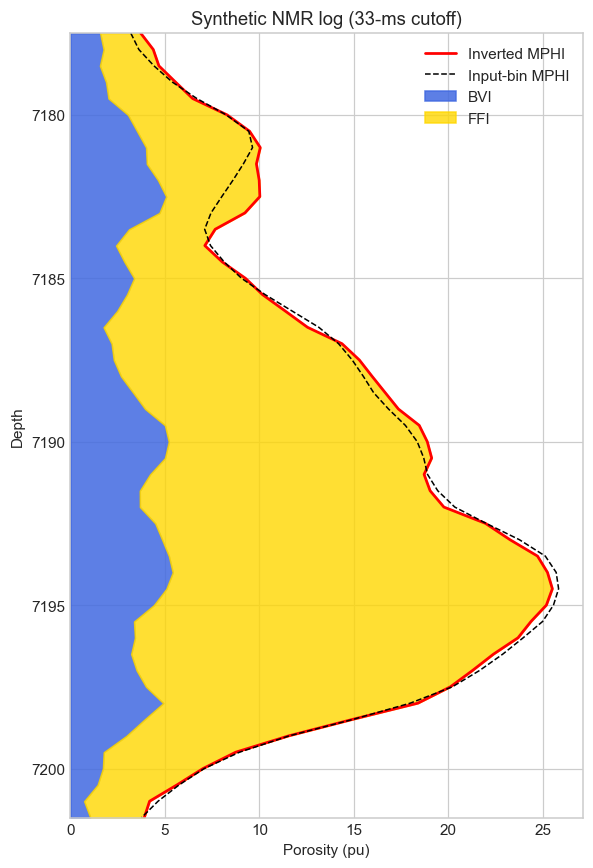

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 8))
ax.plot(recovered_mphi, stacked_depth, color="red", lw=1.8, label="Inverted MPHI")
ax.plot(true_mphi, stacked_depth, color="black", lw=1.0, ls="--", label="Input-bin MPHI")
ax.fill_betweenx(stacked_depth, 0, recovered_bvi, color="royalblue", alpha=0.85,
                 label="BVI")
ax.fill_betweenx(stacked_depth, recovered_bvi, recovered_mphi, color="gold", alpha=0.80,
                 label="FFI")
ax.set_ylim(stacked_depth.max(), stacked_depth.min())
ax.set_xlim(left=0)
ax.set(title=f"Synthetic NMR log ({T2_CUTOFF_MS:g}-ms cutoff)",
       xlabel="Porosity (pu)", ylabel="Depth")
ax.legend(loc="best")
plt.tight_layout()
plt.show()


## 7. Watch the log being built level by level

This four-panel view connects each processing step to the growing NMR log:

1. the unstacked synthetic X/Y acquisition at the representative input depth;
2. the stacked phase-corrected echo, quadrature residual, and inversion fit;
3. the source bins and recovered T2 distribution at that level; and
4. the accumulated BVI, FFI, and MPHI log through the current processed depth.

The distribution panel uses porosity per logarithmic T2 interval. This density
normalization makes the eight-bin input and 64-component inversion visually
comparable even though their individual bin widths differ.

The function can display any single level, while the following cell exports all
levels as a GIF. Setting `CREATE_LEVEL_ANIMATION = False` skips GIF generation.


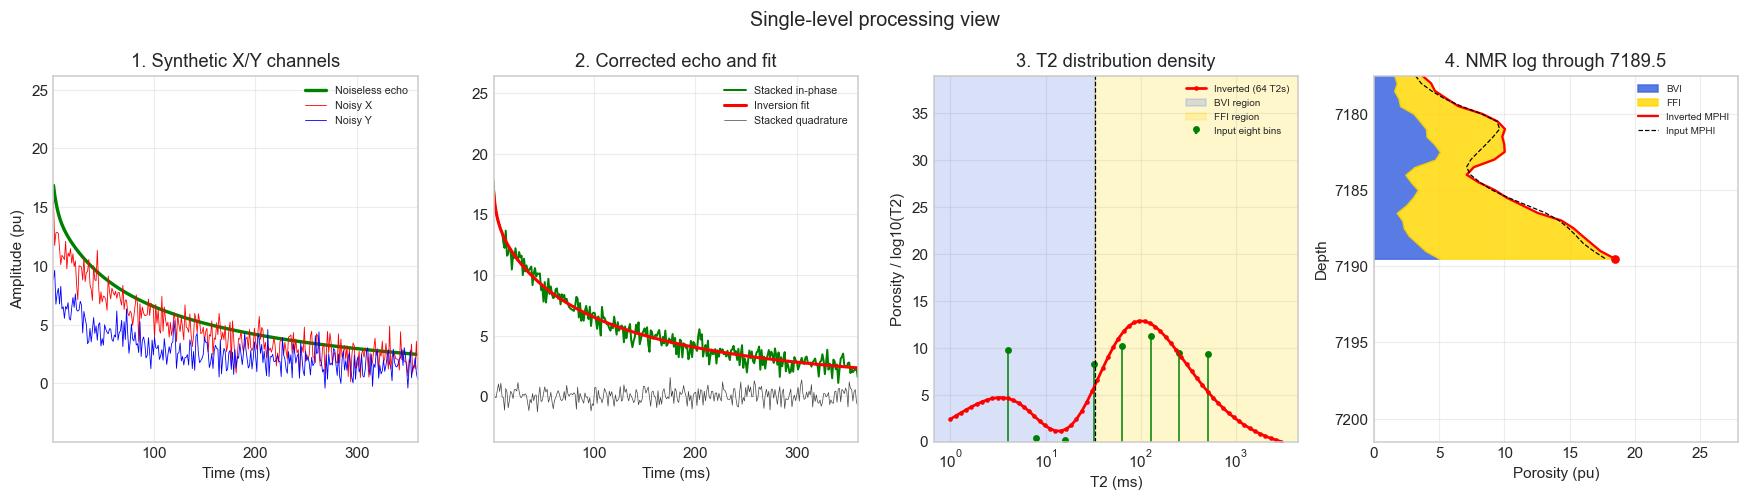

In [14]:
raw_channel_limits = (
    min(x_channel.min(), y_channel.min(), noiseless_echoes.min()),
    max(x_channel.max(), y_channel.max(), noiseless_echoes.max()),
)
corrected_channel_limits = (
    min(stacked_in_phase.min(), stacked_quadrature.min(), fitted_echoes.min()),
    max(stacked_in_phase.max(), stacked_quadrature.max(), fitted_echoes.max()),
)

def padded_limits(limits, fraction=0.06):
    lower, upper = limits
    padding = fraction * max(upper - lower, 1.0)
    return lower - padding, upper + padding


raw_channel_limits = padded_limits(raw_channel_limits)
corrected_channel_limits = padded_limits(corrected_channel_limits)
distribution_ymax = 1.12 * max(
    source_spectral_density.max(), recovered_spectral_density.max(), 1.0
)
log_xmax = 1.08 * max(recovered_mphi.max(), true_mphi.max(), 1.0)
plot_t2_min = min(SOURCE_T2_BIN_MS.min(), INVERSION_T2_MS.min()) / 1.5
plot_t2_max = max(SOURCE_T2_BIN_MS.max(), INVERSION_T2_MS.max()) * 1.5


def draw_processing_level(frame_index, axes):
    if not 0 <= frame_index < len(stacked_depth):
        raise IndexError(
            f"frame_index must be between 0 and {len(stacked_depth) - 1}."
        )

    for axis in axes:
        axis.clear()

    representative_input_row = min(
        frame_index + (STACK_LEVELS - 1) // 2,
        len(depth) - 1,
    )
    current_depth = stacked_depth[frame_index]

    # Panel 1: unstacked synthetic acquisition channels
    axes[0].plot(
        time_ms,
        noiseless_echoes[representative_input_row],
        color="green",
        lw=2.2,
        label="Noiseless echo",
    )
    axes[0].plot(
        time_ms,
        x_channel[representative_input_row],
        color="red",
        lw=0.55,
        label="Noisy X",
    )
    axes[0].plot(
        time_ms,
        y_channel[representative_input_row],
        color="blue",
        lw=0.55,
        label="Noisy Y",
    )
    axes[0].set(
        xlim=(time_ms[0], time_ms[-1]),
        ylim=raw_channel_limits,
        title="1. Synthetic X/Y channels",
        xlabel="Time (ms)",
        ylabel="Amplitude (pu)",
    )
    axes[0].legend(loc="upper right", fontsize=7)

    # Panel 2: stacked phase-corrected echo and its fitted echo
    axes[1].plot(
        time_ms,
        stacked_in_phase[frame_index],
        color="green",
        lw=1.3,
        label="Stacked in-phase",
    )
    axes[1].plot(
        time_ms,
        fitted_echoes[frame_index],
        color="red",
        lw=2.0,
        label="Inversion fit",
    )
    axes[1].plot(
        time_ms,
        stacked_quadrature[frame_index],
        color="black",
        lw=0.45,
        alpha=0.75,
        label="Stacked quadrature",
    )
    axes[1].set(
        xlim=(time_ms[0], time_ms[-1]),
        ylim=corrected_channel_limits,
        title="2. Corrected echo and fit",
        xlabel="Time (ms)",
    )
    axes[1].legend(loc="upper right", fontsize=7)

    # Panel 3: source and recovered T2 distributions
    markerline, stemlines, _ = axes[2].stem(
        SOURCE_T2_BIN_MS,
        source_spectral_density[frame_index],
        linefmt="g-",
        markerfmt="go",
        basefmt=" ",
        label="Input eight bins",
    )
    plt.setp(stemlines, linewidth=1.0)
    plt.setp(markerline, markersize=3.5)
    axes[2].semilogx(
        INVERSION_T2_MS,
        recovered_spectral_density[frame_index],
        color="red",
        lw=1.8,
        marker="o",
        ms=2.0,
        label=f"Inverted ({len(INVERSION_T2_MS)} T2s)",
    )
    axes[2].axvspan(
        plot_t2_min,
        T2_CUTOFF_MS,
        color="royalblue",
        alpha=SHADE_OPACITY,
        label="BVI region",
    )
    axes[2].axvspan(
        T2_CUTOFF_MS,
        plot_t2_max,
        color="gold",
        alpha=SHADE_OPACITY,
        label="FFI region",
    )
    axes[2].axvline(T2_CUTOFF_MS, color="black", ls="--", lw=0.8)
    axes[2].set(
        xlim=(plot_t2_min, plot_t2_max),
        ylim=(0, distribution_ymax),
        title="3. T2 distribution density",
        xlabel="T2 (ms)",
        ylabel="Porosity / log10(T2)",
    )
    axes[2].legend(loc="upper right", fontsize=6.5)

    # Panel 4: accumulated log through this frame
    processed = slice(0, frame_index + 1)
    plot_depth = stacked_depth[processed]
    plot_mphi = recovered_mphi[processed]
    plot_bvi = recovered_bvi[processed]
    axes[3].fill_betweenx(
        plot_depth,
        0,
        plot_bvi,
        color="royalblue",
        alpha=0.88,
        label="BVI",
    )
    axes[3].fill_betweenx(
        plot_depth,
        plot_bvi,
        plot_mphi,
        color="gold",
        alpha=0.82,
        label="FFI",
    )
    axes[3].plot(plot_mphi, plot_depth, color="red", lw=1.5, label="Inverted MPHI")
    axes[3].plot(
        true_mphi[processed],
        plot_depth,
        color="black",
        lw=0.8,
        ls="--",
        label="Input MPHI",
    )
    axes[3].scatter(
        [recovered_mphi[frame_index]],
        [current_depth],
        color="red",
        s=22,
        zorder=5,
    )
    axes[3].set(
        xlim=(0, log_xmax),
        ylim=(stacked_depth.max(), stacked_depth.min()),
        title=f"4. NMR log through {current_depth:.1f}",
        xlabel="Porosity (pu)",
        ylabel="Depth",
    )
    axes[3].legend(loc="upper right", fontsize=6.5)

    for axis in axes:
        axis.grid(True, alpha=0.35)


# Show how to request one level directly.
preview_figure, preview_axes = plt.subplots(1, 4, figsize=(16, 4.6))
draw_processing_level(len(stacked_depth) // 2, preview_axes)
preview_figure.suptitle("Single-level processing view", fontsize=13)
preview_figure.tight_layout()
plt.show()


Wrote /Users/craig/Documents/Codex/NMR_Echo_Train_Phase_Rotation/outputs_to_GitHub/nmr_level_by_level_tutorial.gif


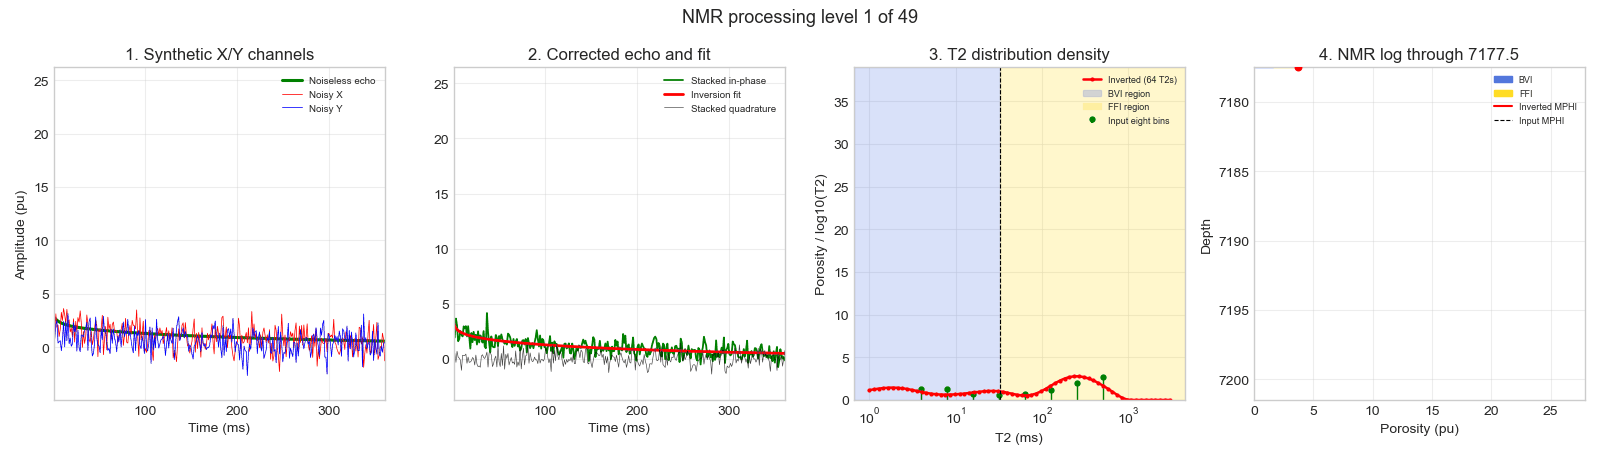

In [15]:
animation_output = Path("nmr_level_by_level_tutorial.gif")

if CREATE_LEVEL_ANIMATION:
    animation_figure, animation_axes = plt.subplots(1, 4, figsize=(16, 4.6))

    def update_animation(frame_index):
        draw_processing_level(frame_index, animation_axes)
        animation_figure.suptitle(
            f"NMR processing level {frame_index + 1} of {len(stacked_depth)}",
            fontsize=13,
        )
        animation_figure.tight_layout()
        return animation_axes


    level_animation = FuncAnimation(
        animation_figure,
        update_animation,
        frames=len(stacked_depth),
        interval=ANIMATION_FRAME_MS,
        repeat=True,
        blit=False,
    )
    level_animation.save(
        animation_output,
        writer=PillowWriter(fps=1000.0 / ANIMATION_FRAME_MS),
        dpi=ANIMATION_DPI,
    )
    plt.close(animation_figure)
    print(f"Wrote {animation_output.resolve()}")
    display(IPythonImage(filename=str(animation_output)))
else:
    print("Level-by-level GIF generation is disabled in the configuration cell.")


## 8. Export the reproducible results

The CSV contains the reconstructed log and recovered bins. The Excel workbook
also contains the corrected in-phase and quadrature echo trains, the input bins,
and the configuration used for this run.


In [16]:
csv_output = Path("nmr_phase_rotation_inversion_results.csv")
xlsx_output = Path("nmr_phase_rotation_inversion_results.xlsx")

results.to_csv(csv_output, index=False)

echo_columns = [f"Echo_{i + 1:03d}_{time_ms[i]:.1f}ms" for i in range(NUM_ECHOES)]
in_phase_export = pd.DataFrame(stacked_in_phase, columns=echo_columns)
in_phase_export.insert(0, "Depth", stacked_depth)
quadrature_export = pd.DataFrame(stacked_quadrature, columns=echo_columns)
quadrature_export.insert(0, "Depth", stacked_depth)

run_metadata = settings.copy()
run_metadata["estimated_phase_deg"] = estimated_phase_deg
run_metadata["correction_phase_deg"] = correction_phase_deg
run_metadata["t2_cutoff_ms"] = T2_CUTOFF_MS
run_metadata["cutoff_rule"] = CUTOFF_PARTITION_MODE

with pd.ExcelWriter(xlsx_output, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Inversion_Log", index=False)
    in_phase_export.to_excel(writer, sheet_name="In_Phase_Echoes", index=False)
    quadrature_export.to_excel(writer, sheet_name="Quadrature_Echoes", index=False)
    pd.DataFrame({
        "Inversion_T2_ms": INVERSION_T2_MS,
        "BVI_fraction": inversion_bvi_fraction,
        "FFI_fraction": inversion_ffi_fraction,
    }).to_excel(
        writer, sheet_name="Inversion_T2_Grid", index=False
    )
    pd.DataFrame({
        "Input_column": BIN_COLUMNS,
        "Source_T2_ms": SOURCE_T2_BIN_MS,
        "BVI_fraction": source_bvi_fraction,
        "FFI_fraction": source_ffi_fraction,
    }).to_excel(
        writer, sheet_name="Input_T2_Bins", index=False
    )
    run_metadata.rename_axis("setting").reset_index(name="value").to_excel(
        writer, sheet_name="Run_Settings", index=False
    )

print(f"Wrote {csv_output.resolve()}")
print(f"Wrote {xlsx_output.resolve()}")


Wrote /Users/craig/Documents/Codex/NMR_Echo_Train_Phase_Rotation/outputs_to_GitHub/nmr_phase_rotation_inversion_results.csv
Wrote /Users/craig/Documents/Codex/NMR_Echo_Train_Phase_Rotation/outputs_to_GitHub/nmr_phase_rotation_inversion_results.xlsx


## Interpretation and limitations

- The phase correction is exact only for a constant phase and ideal quadrature
  channels. Real measurements may need offset, gain, and quadrature-error
  corrections.
- The corrected quadrature channel is a useful residual/QC channel. Calling it
  a pure noise channel is appropriate only under the ideal assumptions above.
- Adjacent-depth stacking improves random-noise precision at the cost of
  vertical resolution.
- `legacy_8_bin` is a controlled bin-recovery test similar to the historical
  workflow that solved directly for porosity in each reporting bin.
- `fine_log` represents the echo as many more fixed T2 components. This is
  closer to a modern T2-spectrum workflow, but it is much more ill-conditioned;
  the additional plotted detail is not automatically additional resolution.
- Fine-grid amplitudes are porosity per log-spaced component. Their sum is
  porosity, but individual amplitudes depend on grid density. Compare spectra
  only when their grid and normalization conventions are known.
- Nonnegativity and smoothness do not determine the correct regularization
  strength. Alpha should be selected using noise-aware validation such as a
  discrepancy criterion, L-curve, cross-validation, or synthetic/core tests.
- Components far beyond the measured time window are weakly constrained. The
  3000-ms upper limit is configurable and should match the acquisition and fluids.
- The T2 cutoff and the definition of partially intersected bins must match the
  acquisition/vendor convention or laboratory calibration before BVI and FFI
  are interpreted petrophysically.
